# 🧪 PARCIAL – UNIDAD 3
## Preparación de los Datos

**Curso:** Minería de Datos  
**Fase CRISP-DM evaluada:** Preparación de los Datos  
**Puntaje total:** 20 puntos

### Datos del grupo
- **Grupo:**  
- **Integrantes:** Glender Samuel Vargas Chipana, Jhair Anthony Josue Choquecota Jimenez, Kendell Svante Norabuena Millones, Joe Miguel Vilca Bayona  
- **Proyecto:** Detección de transacciones asociadas al lavado de activos  
- **Dataset utilizado:** IBM AML-Data (`LI-Small_Trans.csv`)

## Objetivo
Evaluar la capacidad del estudiante para **programar, justificar y reproducir** un proceso de preparación de datos.

### Se evalúa
1. Limpieza y tratamiento de calidad.
2. Transformación y codificación.
3. Ingeniería de características.
4. Selección o reducción de variables.
5. Pipeline reproducible.
6. Dataset final preparado.

> Este parcial evalúa principalmente el **código**. Toda transformación debe mostrar evidencia antes y después.

# 📦 Archivos obligatorios

El grupo debe entregar:

1. **Dataset original**: sin modificaciones.
2. **Dataset en proceso**: versión intermedia con transformaciones aplicadas.
3. **Dataset final**: versión analítica final.

> No sobrescribir el dataset original.

# 0. Configuración inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)

try:                                    # en Colab: monta Drive
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:                     # ejecucion local
    pass

print("✅ Entorno listo")

✅ Entorno listo


# 0.1 Carga del dataset original

In [2]:
# Rutas del proyecto. En Colab usa Drive; en local usa las etapas de datos/ del repositorio:
#   datos/00_fuente   -> CSV sucio, nunca se modifica
#   datos/01_original -> ventana de trabajo exportada sin cambios (entregable 1)
#   datos/02_proceso  -> dataset con transformaciones (entregable 2)
#   datos/03_final    -> dataset analitico final (entregable 3)
RUTA_DRIVE = Path("/content/drive/MyDrive/MineriaData/LI-Small_Trans_sucio.csv")
if RUTA_DRIVE.exists():
    RUTA = RUTA_DRIVE
    SALIDA = RUTA_DRIVE.parent / "salida"
    DESTINO = {etapa: SALIDA for etapa in ("original", "proceso", "final")}
else:
    RAIZ = Path.cwd() if (Path.cwd() / "datos").exists() else Path.cwd().parent
    DATOS = RAIZ / "datos"
    RUTA = DATOS / "00_fuente" / "LI-Small_Trans_sucio.csv"
    DESTINO = {"original": DATOS / "01_original", "proceso": DATOS / "02_proceso", "final": DATOS / "03_final"}
SALTAR = 3_060_000       # ventana del medio del archivo (ordenado por tiempo)
N_FILAS = 1_020_000      # filas de la ventana de trabajo
assert RUTA.exists(), f"No encuentro el CSV: {RUTA.resolve()}"
for carpeta in DESTINO.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print("Archivo:", RUTA.resolve(), "|", round(RUTA.stat().st_size / 1e6), "MB")

Archivo: /home/glender/Glender /ProyectosUNi/DataMining/datos/00_fuente/LI-Small_Trans_sucio.csv | 663 MB


## Carga del archivo

Completa el código según sea CSV o Excel.

Debes crear:

```python
df_original
df_proceso
```

`df_proceso` debe iniciar como una copia del original.

**Alcance:** el CSV sucio completo se conserva como fuente. El archivo `dataset_original.csv` generado por el código es la ventana de trabajo de 1.020.000 filas, reexportada con pandas; no es una copia idéntica del archivo completo.

In [3]:
df_original = pd.read_csv(RUTA, skiprows=range(1, 1 + SALTAR), nrows=N_FILAS, low_memory=False)   # sin dtype: los tipos sucios quedan a la vista
df_proceso = df_original.copy()                                    # el original no se toca
df_original.to_csv(DESTINO["original"] / "dataset_original.csv", index=False)  # entregable 1: original
print("Original:", df_original.shape)

Original: (1020000, 11)


# 0.2 Evidencia inicial — 1 punto

Muestra con código:

- Primeras 5 filas
- Dimensiones
- Tipos
- Nulos totales
- Duplicados exactos

In [4]:
display(df_original.head())
print("Dimensiones:", df_original.shape)
display(df_original.dtypes.to_frame("tipo"))
print("Nulos totales (NaN reales):", int(df_original.isna().sum().sum()))
print("Duplicados exactos:", int(df_original.duplicated().sum()))

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/04 13:22,0123807,811EFB390,NaN,81B8AC220,3342.26,US Dollar,3342.26,US Dollar,Cheque,0
1,2022/09/04 13:17,0123807,811EFB390,018747,81B8AC220,5604.04,US Dollar,5604.04,US Dollar,Credit Card,0
2,2022/09/04 13:16,070,10042B660,0074853,81B9F6110,62961.10,US Dollar,62961.10,US Dollar,Cheque,0
3,2022/09/04 13:03,0221024,817C39630,0070701,81B15C870,2268.05,US Dollar,2268.05,US,Cheque,0
4,2022/09/04 13:18,0221024,817C39630,0070701,81B15C870,2569.93,US Dollar,2569.93,US Dollar,Credit Card,0


Dimensiones: (1020000, 11)


,tipo
Timestamp,str
From Bank,str
Account,str
To Bank,str
Account.1,str
Amount Received,str
Receiving Currency,str
Amount Paid,str
Payment Currency,str
Payment Format,str


Nulos totales (NaN reales): 160369


Duplicados exactos: 20002


### Interpretación inicial
Describe brevemente los principales problemas encontrados.

**Respuesta:** Los montos (`Amount Received/Paid`) y los bancos (`From/To Bank`) aparecen como `object` en vez de numéricos, porque mezclan símbolos (`$`), coma decimal europea (`4.723,06`) y marcas de faltante (`?`, `-`). Hay nulos reales y nulos disfrazados de texto, filas duplicadas, categorías escritas de varias formas (`Cheque`, `CHEQUE`, ` cheque `, `CHE`), montos negativos y extremos, fechas en formatos mezclados o inválidas, y cuentas con espacios o minúsculas.

---
# 1. LIMPIEZA Y TRATAMIENTO DE CALIDAD — 5 puntos

Debes trabajar nulos, duplicados, inconsistencias, valores inválidos y outliers.

## 1.1 Valores nulos — 1.5 puntos

Debes:

1. Calcular cantidad y porcentaje de nulos
2. Seleccionar al menos una variable con nulos
3. Ddecidir eliminar, imputar o conservar
4. Ejecutar el tratamiento
5. Mostrar evidencia antes y después

In [5]:
TOKENS_NULOS = ["?", "-", "", "N/A", "n/a", "NA", "null", "NULL", "None", "nan"]

def reporte_nulos(df):
    n = df.isna().sum()
    return pd.DataFrame({"nulos": n, "%": (100 * n / len(df)).round(2)})

def limpiar_nulos(df):
    df = df.copy()
    obj = df.select_dtypes("object").columns
    df[obj] = df[obj].apply(lambda s: s.str.strip()).replace(TOKENS_NULOS, np.nan)   # nulos disfrazados -> NaN
    # monedas: una se completa con la otra (casi siempre coinciden); el resto -> categoria explicita
    df["Payment Currency"] = df["Payment Currency"].fillna(df["Receiving Currency"])
    df["Receiving Currency"] = df["Receiving Currency"].fillna(df["Payment Currency"])
    for c in ["Payment Currency", "Receiving Currency", "Payment Format"]:
        df[c] = df[c].fillna("Desconocido")
    # bancos: son identificadores, no se pueden imputar -> eliminar fila
    return df.dropna(subset=["From Bank", "To Bank"]).reset_index(drop=True)

antes = reporte_nulos(df_proceso)
df_proceso = limpiar_nulos(df_proceso)
display(antes.join(reporte_nulos(df_proceso), lsuffix="_antes", rsuffix="_despues"))
print("Filas:", len(df_original), "->", len(df_proceso))
print("Montos y Timestamp siguen con nulos: se tratan en 1.3 y 2.1, cuando ya tienen tipo correcto.")

/tmp/ipykernel_135964/3691102373.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj = df.select_dtypes("object").columns


/tmp/ipykernel_135964/3691102373.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(antes.join(reporte_nulos(df_proceso), lsuffix="_antes", rsuffix="_despues"))


,nulos_antes,%_antes,nulos_despues,%_despues
Timestamp,6653,0.65,9552,0.98
From Bank,13548,1.33,0,0.00
Account,0,0.00,0,0.00
To Bank,13538,1.33,0,0.00
Account.1,0,0.00,0,0.00
Amount Received,27404,2.69,39290,4.01
Receiving Currency,19813,1.94,0,0.00
Amount Paid,27220,2.67,39057,3.99
Payment Currency,19301,1.89,0,0.00
Payment Format,32892,3.22,0,0.00


Filas: 1020000 -> 979565
Montos y Timestamp siguen con nulos: se tratan en 1.3 y 2.1, cuando ya tienen tipo correcto.


### Justificación
¿Por qué elegiste ese tratamiento?

**Respuesta:** Primero se convierten a `NaN` los nulos disfrazados (`?`, `-`, `N/A`, vacío); sin eso, `isna()` los subestima. **Monedas:** casi siempre `Receiving` y `Payment` coinciden, así que una completa a la otra; lo que queda va a `Desconocido`. **Payment Format:** categoría `Desconocido`, para no perder filas ni inventar un valor. **Bancos:** son identificadores y no existe forma defendible de imputarlos, por lo que se eliminan esas filas (pérdida pequeña, ~4 %).

## 1.2 Duplicados — 1 punto

Debes:

1. Detectar duplicados exactos
2. Revisar una llave lógica
3. Decidir si se eliminan o conservan
4. Demostrar el resultado

In [6]:
def quitar_duplicados(df):
    return df.drop_duplicates().reset_index(drop=True)

LLAVE = ["Timestamp", "Account", "Account.1", "Amount Paid"]   # llave logica de una transaccion
print("Duplicados exactos antes:", int(df_proceso.duplicated().sum()))
print("Duplicados por llave logica antes:", int(df_proceso.duplicated(LLAVE).sum()))
n0 = len(df_proceso)
df_proceso = quitar_duplicados(df_proceso)
print("Duplicados exactos despues:", int(df_proceso.duplicated().sum()))
print("Duplicados por llave logica despues:", int(df_proceso.duplicated(LLAVE).sum()))
print("Filas eliminadas:", n0 - len(df_proceso))

Duplicados exactos antes: 19239


Duplicados por llave logica antes: 19273


Duplicados exactos despues: 0


Duplicados por llave logica despues: 34
Filas eliminadas: 19239


### Justificación

**Respuesta:** Una fila idéntica en todas las columnas (incluido el timestamp al minuto) es una copia, no una transacción nueva, e inflaría los conteos y sesgaría un modelo. Se eliminan los exactos conservando la primera aparición. Los que solo coinciden en la llave lógica (mismo minuto, cuentas y monto) se **conservan**: pueden ser transacciones legítimas repetidas, y en este dominio la repetición puede ser justo la señal que se busca.

## 1.3 Consistencia y valores inválidos — 1.5 puntos

Selecciona al menos una variable y:

- Detecta inconsistencias o valores inválidos
- Define una regla
- Aplica la corrección
- Valida el resultado

In [7]:
FORMATOS = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]
MONEDAS = ["Australian Dollar", "Bitcoin", "Brazil Real", "Canadian Dollar", "Euro", "Mexican Peso", "Ruble",
           "Rupee", "Saudi Riyal", "Shekel", "Swiss Franc", "UK Pound", "US Dollar", "Yen", "Yuan"]

def _canon(s, validos):
    """mayusculas/espacios/abreviaturas ('REI', 'EUR', 'US') -> categoria valida, por prefijo de 3 letras"""
    mapa = {v[:3].lower().strip(): v for v in validos}
    k = s.str.lower().str.strip().str[:3].str.strip()
    return k.map(mapa).fillna("Desconocido")

def _a_numero(s):
    """'$1,234.56' | '1.234,56' (coma europea) | '-12' | '3195403.0' -> float"""
    t = s.astype(str).str.strip().str.replace("$", "", regex=False)
    euro = t.str.match(r"^-?\d{1,3}(\.\d{3})*,\d{2}$")
    t = t.mask(euro, t.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(t.str.replace(",", "", regex=False), errors="coerce")

def normalizar(df):
    df = df.copy()
    df["Payment Format"] = _canon(df["Payment Format"], FORMATOS)
    for c in ["Payment Currency", "Receiving Currency"]:
        df[c] = _canon(df[c], MONEDAS)
    for c in ["Account", "Account.1"]:
        df[c] = df[c].str.strip().str.upper()
    for c in ["Amount Paid", "Amount Received"]:
        df[c] = _a_numero(df[c]).abs()                      # un monto no puede ser negativo -> error de signo
    misma = df["Payment Currency"] == df["Receiving Currency"]   # montos faltantes: del otro lado, si no hay cambio de moneda
    df["Amount Paid"] = df["Amount Paid"].fillna(df["Amount Received"].where(misma))
    df["Amount Received"] = df["Amount Received"].fillna(df["Amount Paid"].where(misma))
    for a, m in [("Amount Paid", "Payment Currency"), ("Amount Received", "Receiving Currency")]:
        df[a] = df[a].fillna(df.groupby(m)[a].transform("median")).fillna(df[a].median())
    return df

antes = df_proceso.copy()
df_proceso = normalizar(df_proceso)

print("Payment Format ANTES:", antes["Payment Format"].nunique(), "valores distintos ->", df_proceso["Payment Format"].nunique(), "DESPUES")
display(pd.concat([antes["Payment Format"].value_counts().rename("antes"),
                   df_proceso["Payment Format"].value_counts().rename("despues")], axis=1).fillna(0).astype(int))
print("Monedas:", antes["Payment Currency"].nunique(), "->", df_proceso["Payment Currency"].nunique(),
      "| Cuentas distintas:", antes["Account"].nunique(), "->", df_proceso["Account"].nunique())
print("Amount Paid: tipo", antes["Amount Paid"].dtype, "->", df_proceso["Amount Paid"].dtype,
      "| con '$':", int(antes["Amount Paid"].astype(str).str.contains("$", regex=False).sum()),
      "| negativos corregidos:", int(antes["Amount Paid"].astype(str).str.startswith("-").sum()))
print("Nulos en montos despues:", int(df_proceso[["Amount Paid", "Amount Received"]].isna().sum().sum()))
assert df_proceso["Payment Format"].isin(FORMATOS + ["Desconocido"]).all()

Payment Format ANTES: 25 valores distintos -> 7 DESPUES


,antes,despues
Payment Format,,
Cheque,342371,364431
Credit Card,253108,269278
ACH,107235,109374
Cash,88666,94218
Desconocido,47539,48025
Bitcoin,39160,41675
Wire,31354,33325
CHEQUE,7422,0
CHE,7332,0


Monedas: 62 -> 16 | Cuentas distintas: 185952 -> 171844
Amount Paid: tipo str -> float64 | con '$': 18414 | negativos corregidos: 8064
Nulos en montos despues: 0


### Regla aplicada

**Respuesta:** (1) Categorías: se normaliza por las 3 primeras letras sin mayúsculas ni espacios y se mapea al valor oficial (`REI`, ` reinvestment ` → `Reinvestment`); lo que no calza queda `Desconocido`. (2) Cuentas: `strip` + mayúsculas. (3) Montos: se quita `$` y separador de miles, se detecta la coma decimal europea y se convierte a `float`; el valor absoluto corrige negativos (error de signo, un monto no puede ser negativo). (4) Montos faltantes: se copian del otro lado si no hubo cambio de moneda; si no, mediana de su moneda. Se valida con `assert` y con la caída de categorías distintas.

## 1.4 Outliers — 1 punto

Selecciona al menos una variable numérica y:

1. Detecta posibles outliers
2. Utiliza IQR, boxplot u otro método justificable
3. Decide conservar, excluir, transformar o separar
4. Justifica la decisión

Atipicos: 33709 (3.51 %)
Max Amount Paid: 1,727,505,625,070 | mediana: 1,221.90


/tmp/ipykernel_135964/1895028277.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0].boxplot(usd["Amount Paid"], vert=False); ax[0].set_title("USD - escala lineal")
/tmp/ipykernel_135964/1895028277.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(np.log1p(usd["Amount Paid"]), vert=False); ax[1].set_title("USD - log1p")


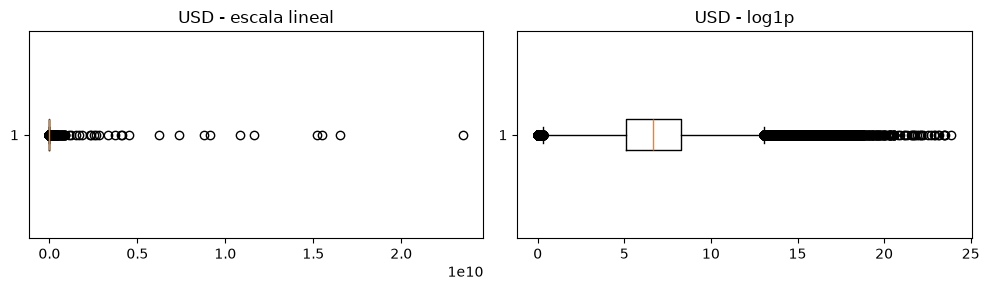

In [8]:
def marcar_atipicos(df):
    """IQR sobre log(monto) por moneda: los montos tienen cola muy larga y en escala lineal el IQR marcaria casi todo"""
    df = df.copy()
    lg = np.log1p(df["Amount Paid"])
    g = lg.groupby(df["Payment Currency"])
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    iqr = q3 - q1
    df["monto_atipico"] = ((lg < q1 - 1.5 * iqr) | (lg > q3 + 1.5 * iqr)).astype("int8")
    return df

df_proceso = marcar_atipicos(df_proceso)
n = int(df_proceso["monto_atipico"].sum())
print(f"Atipicos: {n} ({100 * n / len(df_proceso):.2f} %)")
print("Max Amount Paid:", f"{df_proceso['Amount Paid'].max():,.0f}", "| mediana:", f"{df_proceso['Amount Paid'].median():,.2f}")
usd = df_proceso[df_proceso["Payment Currency"] == "US Dollar"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].boxplot(usd["Amount Paid"], vert=False); ax[0].set_title("USD - escala lineal")
ax[1].boxplot(np.log1p(usd["Amount Paid"]), vert=False); ax[1].set_title("USD - log1p")
plt.tight_layout(); plt.show()

### Decisión sobre los outliers

**Respuesta:** Se detectan con IQR sobre `log1p(monto)` por moneda (en escala lineal la cola larga haría que casi todo parezca atípico) y se **conservan marcados** en `monto_atipico`, sin eliminarlos. En lavado de activos los montos extremos pueden ser justo la señal buscada, y borrarlos eliminaría casos positivos. Para que no dominen las distancias o los coeficientes de un modelo se comprimen con `log1p` en 2.3. Limitación: una parte de los extremos puede ser error de captura y no se puede distinguir sin validar con la fuente.

---
# 2. TRANSFORMACIÓN Y CODIFICACIÓN — 4 puntos

## 2.1 Conversión de tipos — 1 punto

Identifica al menos una variable cuyo tipo técnico no represente correctamente su significado.

Ejemplos:

- Número guardado como `object`;
- Fecha almacenada como texto.

Debes mostrar el tipo antes y después.

In [9]:
def convertir_tipos(df):
    df = df.copy()
    t = pd.to_datetime(df["Timestamp"], format="%Y/%m/%d %H:%M", errors="coerce")      # formato oficial
    for f in ("%d-%m-%Y %H:%M", "%Y-%m-%dT%H:%M:%S"):                                    # formatos alternativos
        t = t.fillna(pd.to_datetime(df["Timestamp"], format=f, errors="coerce"))
    df["Timestamp"] = t
    df = df.dropna(subset=["Timestamp"])                                                 # fecha irrecuperable
    for c in ["From Bank", "To Bank"]:
        df[c] = pd.to_numeric(df[c]).astype("int64")
    return df.reset_index(drop=True)

tipos_antes = df_proceso[["Timestamp", "From Bank", "To Bank", "Amount Paid"]].dtypes
n0 = len(df_proceso)
df_proceso = convertir_tipos(df_proceso)
display(pd.DataFrame({"antes": tipos_antes, "despues": df_proceso[tipos_antes.index].dtypes}))
print("Filas con fecha invalida/nula eliminadas:", n0 - len(df_proceso))
print("Rango de fechas:", df_proceso["Timestamp"].min(), "->", df_proceso["Timestamp"].max())

,antes,despues
Timestamp,str,datetime64[us]
From Bank,str,int64
To Bank,str,int64
Amount Paid,float64,float64


Filas con fecha invalida/nula eliminadas: 14125
Rango de fechas: 2022-09-04 13:00:00 -> 2022-09-13 16:09:00


## 2.2 Codificación categórica — 1.5 puntos

Aplica una técnica adecuada:

- Binaria
- Ordinal
- One-Hot Encoding

Debes justificar la técnica elegida.

In [10]:
def codificar(df):
    d = pd.get_dummies(df["Payment Format"], prefix="fmt", dtype="int8")
    return pd.concat([df, d], axis=1)

df_proceso = codificar(df_proceso)
display(df_proceso.filter(like="fmt_").head())
display(df_proceso.filter(like="fmt_").sum().to_frame("filas"))

,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire
0,0,0,0,0,1,0,0
1,0,0,0,1,0,0,0
2,0,0,0,1,0,0,0
3,0,0,0,0,1,0,0
4,0,0,0,1,0,0,0


,filas
fmt_ACH,107770
fmt_Bitcoin,41075
fmt_Cash,92714
fmt_Cheque,359157
fmt_Credit Card,265335
fmt_Desconocido,47336
fmt_Wire,32814


### Justificación

**Respuesta:** `Payment Format` es categórica **nominal** (no hay orden entre Cheque, Wire, ACH...) y de baja cardinalidad (hasta 7 valores; 6 en esta ventana de datos, más `Desconocido`), por eso One-Hot: no inventa un orden falso como lo haría un código numérico y no explota el número de columnas. Las monedas (15 valores) no se codifican uno a uno; se resumen en `misma_moneda` (sección 3).

## 2.3 Escalamiento o discretización — 1.5 puntos

Aplica al menos una:

- Min-Max
- StandardScaler
- Discretización / binning

Muestra evidencia antes y después.

,Amount Paid (antes),monto_z (despues)
count,9.462010e+05,9.462010e+05
mean,8.870261e+06,-4.998275e-17
std,2.341235e+09,1.000000e+00
min,0.000000e+00,-2.188262e+00
25%,1.805500e+02,-6.126382e-01
50%,1.221790e+03,-3.486968e-02
75%,9.268550e+03,5.787157e-01
max,1.727506e+12,6.347198e+00


Asimetria antes: 576.3 | despues: 0.27


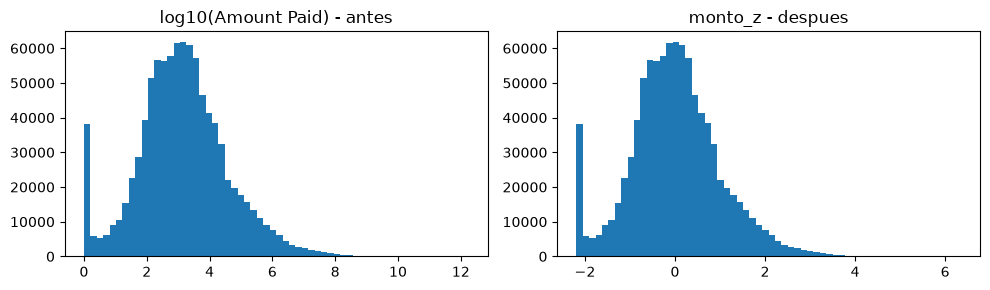

In [11]:
def escalar(df):
    df = df.copy()
    df["log_monto_pagado"] = np.log1p(df["Amount Paid"])                  # comprime la cola larga
    df["monto_z"] = (df["log_monto_pagado"] - df["log_monto_pagado"].mean()) / df["log_monto_pagado"].std()
    return df

antes = df_proceso["Amount Paid"]
df_proceso = escalar(df_proceso)
display(pd.DataFrame({"Amount Paid (antes)": antes.describe(), "monto_z (despues)": df_proceso["monto_z"].describe()}))
print("Asimetria antes:", round(antes.skew(), 1), "| despues:", round(df_proceso["monto_z"].skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(np.log10(antes + 1), bins=60); ax[0].set_title("log10(Amount Paid) - antes")
ax[1].hist(df_proceso["monto_z"], bins=60); ax[1].set_title("monto_z - despues")
plt.tight_layout(); plt.show()

### Justificación

**Respuesta:** El monto tiene asimetría extrema (mediana de miles frente a máximos de billones). Se aplica `log1p` para reducir la cola y luego Z-score (media 0, desviación 1) para que quede en una escala comparable con las variables binarias. Z-score en vez de Min-Max porque Min-Max quedaría aplastado por los máximos. Nota: media y desviación se calculan sobre toda la muestra; antes de entrenar un modelo hay que ajustarlas solo con el conjunto de entrenamiento para evitar fuga.

---
# 3. INGENIERÍA DE CARACTERÍSTICAS — 3 puntos

Crea al menos **2 nuevas variables** útiles para el proyecto.

Cada una debe tener:

- Variables de origen
- Fórmula o lógica
- Código
- Interpretación
- Utilidad

## Variable nueva 1

In [12]:
def crear_variables(df):
    df = df.copy()
    df["misma_moneda"] = (df["Receiving Currency"] == df["Payment Currency"]).astype("int8")
    df["hora"] = df["Timestamp"].dt.hour.astype("int8")
    return df

df_proceso = crear_variables(df_proceso)
display(df_proceso[["Receiving Currency", "Payment Currency", "misma_moneda"]].head())
display(df_proceso.groupby("misma_moneda")["Is Laundering"].agg(["count", "mean"]).rename(columns={"mean": "tasa_lavado"}))

,Receiving Currency,Payment Currency,misma_moneda
0,US Dollar,US Dollar,1
1,US Dollar,US Dollar,1
2,US Dollar,US Dollar,1
3,US Dollar,US Dollar,1
4,US Dollar,US Dollar,1


,count,tasa_lavado
misma_moneda,,
0,14875,0.000000
1,931326,0.000703


**Origen / fórmula:** `misma_moneda = (Receiving Currency == Payment Currency)` → 1 si no hay cambio de moneda.
**Interpretación:** 0 indica una transferencia con conversión de divisa (cruce de moneda/frontera).
**Utilidad:** resume 2 columnas categóricas de 15 valores en un binario, y los cruces de moneda son un patrón habitual en esquemas de lavado.

## Variable nueva 2

In [13]:
display(df_proceso[["Timestamp", "hora"]].head())
display(df_proceso.groupby("hora")["Is Laundering"].agg(["count", "mean"]).rename(columns={"mean": "tasa_lavado"}).T)

,Timestamp,hora
0,2022-09-04 13:17:00,13
1,2022-09-04 13:16:00,13
2,2022-09-04 13:03:00,13
3,2022-09-04 13:18:00,13
4,2022-09-04 13:29:00,13


hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
count,88446.000000,50406.000000,50661.000000,50430.000000,49884.000000,49455.000000,49799.000000,42445.00000,24795.000000,25087.000000,25182.000000,24979.000000,24808.000000,33895.000000,35217.000000,35416.000000,35760.000000,35431.000000,36068.000000,35434.000000,35209.000000,36108.000000,36054.000000,35232.000000
tasa_lavado,0.000271,0.000476,0.000454,0.000357,0.000381,0.000607,0.000382,0.00066,0.000847,0.000917,0.000874,0.001121,0.001008,0.001446,0.001164,0.001214,0.000727,0.000847,0.000943,0.000931,0.000852,0.000609,0.000582,0.000624


**Origen / fórmula:** `hora = Timestamp.dt.hour` (0–23).
**Interpretación:** hora del día en que ocurre la transacción.
**Utilidad:** el `Timestamp` completo es único por fila y no sirve como predictor; la hora captura patrones de actividad (p. ej. operaciones de madrugada).

---
# 4. SELECCIÓN O REDUCCIÓN DE VARIABLES — 2 puntos

Debes identificar:

- Todas variables que conservarás
- Las variable que excluirás
- Las variable que transformarás o reemplazarás por una derivada.

In [14]:
EXCLUIR = ["Timestamp", "From Bank", "To Bank", "Account", "Account.1", "Amount Received",
           "Receiving Currency", "Payment Currency", "Payment Format", "Amount Paid", "log_monto_pagado"]

def seleccionar(df):
    return df.drop(columns=EXCLUIR)

conservar = [c for c in df_proceso.columns if c not in EXCLUIR]
print("CONSERVAR:", conservar)
print("EXCLUIR  :", EXCLUIR)
print("REEMPLAZADAS por derivada: Timestamp->hora | Receiving/Payment Currency->misma_moneda | Payment Format->fmt_* | Amount Paid->monto_z")

CONSERVAR: ['Is Laundering', 'monto_atipico', 'fmt_ACH', 'fmt_Bitcoin', 'fmt_Cash', 'fmt_Cheque', 'fmt_Credit Card', 'fmt_Desconocido', 'fmt_Wire', 'monto_z', 'misma_moneda', 'hora']
EXCLUIR  : ['Timestamp', 'From Bank', 'To Bank', 'Account', 'Account.1', 'Amount Received', 'Receiving Currency', 'Payment Currency', 'Payment Format', 'Amount Paid', 'log_monto_pagado']
REEMPLAZADAS por derivada: Timestamp->hora | Receiving/Payment Currency->misma_moneda | Payment Format->fmt_* | Amount Paid->monto_z


## Revisión de Data Leakage

¿Existe alguna variable que contenga información disponible solo después del evento que quieres analizar?

**Respuesta:** `Is Laundering` es la **etiqueta** (lo que se quiere predecir) y solo debe usarse como objetivo, nunca como predictora. Ninguna otra columna es posterior al evento. `Account` y los bancos se excluyen por ser identificadores de alta cardinalidad: un modelo memorizaría cuentas concretas y no generalizaría. `Amount Received` se excluye por ser casi redundante con `Amount Paid`. El escalado debe ajustarse solo con entrenamiento al modelar.

---
# 5. DATASET EN PROCESO — 1 punto

En este punto debes guardar una versión intermedia.

Debe evidenciar las transformaciones realizadas antes de construir el dataset final.

In [15]:
df_proceso.to_csv(DESTINO["proceso"] / "dataset_proceso.csv", index=False)     # entregable 2
print("Guardado:", DESTINO["proceso"] / "dataset_proceso.csv")

Guardado: /home/glender/Glender /ProyectosUNi/DataMining/datos/02_proceso/dataset_proceso.csv


## Evidencia del dataset en proceso

Muestra:

- Dimensiones
- Primeras filas
- Nulos
- Duplicados
- Tipos

In [16]:
print("Dimensiones:", df_proceso.shape)
display(df_proceso.head())
print("Nulos:", int(df_proceso.isna().sum().sum()), "| Duplicados:", int(df_proceso.duplicated().sum()))
display(df_proceso.dtypes.to_frame("tipo").T)

Dimensiones: (946201, 23)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,monto_atipico,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire,log_monto_pagado,monto_z,misma_moneda,hora
0,2022-09-04 13:17:00,123807,811EFB390,18747,81B8AC220,5604.04,US Dollar,5604.04,US Dollar,Credit Card,0,0,0,0,0,0,1,0,0,8.631421,0.426328,1,13
1,2022-09-04 13:16:00,70,10042B660,74853,81B9F6110,62961.10,US Dollar,62961.10,US Dollar,Cheque,0,0,0,0,0,1,0,0,0,11.050288,1.159041,1,13
2,2022-09-04 13:03:00,221024,817C39630,70701,81B15C870,2268.05,US Dollar,2268.05,US Dollar,Cheque,0,0,0,0,0,1,0,0,0,7.727117,0.152401,1,13
3,2022-09-04 13:18:00,221024,817C39630,70701,81B15C870,2569.93,US Dollar,2569.93,US Dollar,Credit Card,0,0,0,0,0,0,1,0,0,7.852023,0.190237,1,13
4,2022-09-04 13:29:00,226290,80C0B9770,58500,81BB1DE90,65406.67,US Dollar,65406.67,US Dollar,Cheque,0,0,0,0,0,1,0,0,0,11.088395,1.170584,1,13


Nulos: 0 | Duplicados: 1


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,monto_atipico,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire,log_monto_pagado,monto_z,misma_moneda,hora
tipo,datetime64[us],int64,str,int64,str,float64,str,float64,str,str,int64,int8,int8,int8,int8,int8,int8,int8,int8,float64,float64,int8,int8


---
# 6. PIPELINE REPRODUCIBLE — 2 puntos

Organiza tu proceso en una función para que pueda ejecutarse nuevamente desde el dataset original.

In [17]:
def preparar_datos(df):
    # Crear copia para no modificar el original
    df = df.copy()

    # 1. Limpieza
    df = limpiar_nulos(df)
    df = quitar_duplicados(df)
    df = normalizar(df)
    df = marcar_atipicos(df)

    # 2. Conversión de tipos
    df = convertir_tipos(df)

    # 3. Transformación / codificación
    df = codificar(df)
    df = escalar(df)

    # 4. Feature Engineering
    df = crear_variables(df)

    # 5. Selección de variables
    df = seleccionar(df)

    return df

### Ejecuta el pipeline

Debe producir el mismo resultado esperado al partir nuevamente del dataset original.

In [18]:
df_final_reproducible = preparar_datos(df_original)     # desde el original, sin pasos manuales
print("Pipeline:", df_final_reproducible.shape)

/tmp/ipykernel_135964/3691102373.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj = df.select_dtypes("object").columns


Pipeline: (946201, 12)


---
# 7. DATASET FINAL PREPARADO — 2 puntos

## 7.1 Construcción del dataset final

In [19]:
df_final = seleccionar(df_proceso)
pd.testing.assert_frame_equal(df_final_reproducible, df_final)   # el pipeline reproduce el resultado exacto
print("✅ El pipeline reproduce exactamente el dataset final:", df_final.shape)

✅ El pipeline reproduce exactamente el dataset final: (946201, 12)


## 7.2 Validación final

Debes mostrar:

- Dimensiones
- Nulos
- Duplicados
- Tipos
- Columnas finales

> Nota: al quitar identificadores y timestamp, muchas filas distintas quedan iguales en las columnas finales; esos "duplicados" **no se eliminan** porque son transacciones diferentes, solo comparten valores en las variables conservadas.

In [20]:
print("Dimensiones:", df_final.shape)
print("Nulos:", int(df_final.isna().sum().sum()), "| Duplicados:", int(df_final.duplicated().sum()))
display(df_final.dtypes.to_frame("tipo").T)
print("Columnas finales:", list(df_final.columns))
display(df_final.head())

Dimensiones: (946201, 12)
Nulos: 0 | Duplicados: 42276


,Is Laundering,monto_atipico,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire,monto_z,misma_moneda,hora
tipo,int64,int8,int8,int8,int8,int8,int8,int8,int8,float64,int8,int8


Columnas finales: ['Is Laundering', 'monto_atipico', 'fmt_ACH', 'fmt_Bitcoin', 'fmt_Cash', 'fmt_Cheque', 'fmt_Credit Card', 'fmt_Desconocido', 'fmt_Wire', 'monto_z', 'misma_moneda', 'hora']


,Is Laundering,monto_atipico,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire,monto_z,misma_moneda,hora
0,0,0,0,0,0,0,1,0,0,0.426328,1,13
1,0,0,0,0,0,1,0,0,0,1.159041,1,13
2,0,0,0,0,0,1,0,0,0,0.152401,1,13
3,0,0,0,0,0,0,1,0,0,0.190237,1,13
4,0,0,0,0,0,1,0,0,0,1.170584,1,13


## 7.3 Comparación obligatoria

Compara:

- Original
- Proceso
- Final

In [21]:
def resumen_dataset(df, nombre):
    return {
        "Dataset": nombre,
        "Filas": len(df),
        "Columnas": df.shape[1],
        "Nulos": int(df.isnull().sum().sum()),
        "Duplicados": int(df.duplicated().sum()),
        "Numericas": len(df.select_dtypes(include=np.number).columns),
        "No_numericas": len(df.select_dtypes(exclude=np.number).columns)
    }

comparacion = pd.DataFrame([
    resumen_dataset(df_original, "Original"),
    resumen_dataset(df_proceso, "Proceso"),
    resumen_dataset(df_final, "Final")
])
display(comparacion)

,Dataset,Filas,Columnas,Nulos,Duplicados,Numericas,No_numericas
0,Original,1020000,11,160369,20002,1,10
1,Proceso,946201,23,0,1,17,6
2,Final,946201,12,0,42276,12,0


## 7.4 Guarda el dataset final

In [22]:
df_final.to_csv(DESTINO["final"] / "dataset_final.csv", index=False)     # entregable 3
print("Guardado:", DESTINO["final"] / "dataset_final.csv")

Guardado: /home/glender/Glender /ProyectosUNi/DataMining/datos/03_final/dataset_final.csv


---
# 8. CONCLUSIÓN TÉCNICA OBLIGATORIA

Máximo 8 líneas.

Responde:

1. ¿Cuáles fueron los principales problemas?
2. ¿Qué transformaciones tuvieron mayor impacto?
3. ¿Qué variables nuevas fueron creadas?
4. ¿Qué variables fueron descartadas?
5. ¿El dataset final está preparado para una etapa posterior?
6. ¿Qué limitaciones permanecen?

### Respuesta
1. Nulos (reales y disfrazados como `?`/`-`), duplicados, categorías mal escritas, montos como texto (`$`, coma europea, negativos), fechas en varios formatos y outliers.
2. Normalizar montos y categorías (recupera tipo numérico y reduce categorías) y el `log1p` + Z-score del monto, que corrige la asimetría extrema.
3. `misma_moneda`, `hora`, `monto_atipico`, `monto_z` y las dummies `fmt_*`.
4. Identificadores (cuentas, bancos, `Timestamp`), `Amount Received` y las columnas originales ya reemplazadas por derivadas.
5. Sí: sin nulos ni duplicados, todo numérico y reproducible con `preparar_datos`; la etiqueta `Is Laundering` queda como objetivo.
6. La clase positiva es ínfima (<0.1 %), por lo que habrá que manejar el desbalance; se trabajó con una muestra; escalado ajustado sobre toda la muestra; los atípicos se conservaron sin distinguir error de señal.

---
# ✅ CHECKLIST DE ENTREGA

- [ ] Notebook `.ipynb` ejecutado
- [ ] Dataset original
- [ ] Dataset en proceso
- [ ] Dataset final
- [ ] Evidencia antes y después
- [ ] Código reproducible
- [ ] Comparación Original vs Proceso vs Final
- [ ] Justificación de decisiones
- [ ] Conclusión técnica

# 📊 RÚBRICA

| Bloque | Puntaje |
|---|---:|
| Evidencia inicial | 1 |
| Limpieza y tratamiento de calidad | 5 |
| Transformación y codificación | 4 |
| Ingeniería de características | 3 |
| Selección o reducción de variables | 2 |
| Dataset en proceso | 1 |
| Pipeline reproducible | 2 |
| Dataset final preparado | 2 |
| **TOTAL** | **20** |

### Regla
- Código correcto sin justificación: no obtiene puntaje completo.
- Explicación sin evidencia de ejecución: no obtiene puntaje completo.
- El dataset original no debe ser modificado directamente.